# Predicting Depression in Students via Various factors

In [32]:
!pip install openml


In [33]:
import sklearn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import openml

import warnings
warnings.filterwarnings('ignore')

## Introduction

For this assignment I am using a dataset  found on openML, it is about depression in students. I was mainly interested in this due to the fact that it seems very prevalent in todays time as well as it seems like something that doesn not get talked about frequently in younger generations, so I wanted to see what factors would allow us to predict depression in the student body better as a whole. Though while I cannot tell you exaclty where to go to gather more information, I do have this information here from a similar article that was published:https://thescipub.com/pdf/jcssp.2024.121.128.pdf. I also enjoy this dataset due to the various facotrs that they have available to determine things, such as cities, professions, academic pressure, work pressure, CGPA, Study satisfaction, job satisfaction, sleep duration, degree, dietary habits, suicidal habits, work/study hours, financial stress and family histories of mental illness. I think these are all very important to keep track of.

## Getting the data
Since it is on openML I will use a method I implemented last project

In [34]:
import requests

depress = openml.datasets.get_dataset(46874)
X, y, categorical_indicator, attribute_names = depress.get_data(target=depress.default_target_attribute)


df = X.copy()
df['target'] = y

print("Dataset shape:", df.shape)
print("\nFirst few rows:")
df.head()

Dataset shape: (27901, 17)

First few rows:


,Gender,Age,City,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,target
0,Male,33,Visakhapatnam,Student,5,0,8.97,2,0,5-6 hours,Healthy,B.Pharm,Yes,3,1.0,No,1
1,Female,24,Bangalore,Student,2,0,5.90,5,0,5-6 hours,Moderate,BSc,No,3,2.0,Yes,0
2,Male,31,Srinagar,Student,3,0,7.03,5,0,Less than 5 hours,Healthy,BA,No,9,1.0,Yes,0
3,Female,28,Varanasi,Student,3,0,5.59,2,0,7-8 hours,Moderate,BCA,Yes,4,5.0,Yes,1
4,Female,25,Jaipur,Student,4,0,8.13,3,0,5-6 hours,Moderate,M.Tech,Yes,1,1.0,No,0


## A small exploration

In [35]:
df.shape

(27901, 17)

In [36]:
df.tail()

,Gender,Age,City,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,target
27896,Female,27,Surat,Student,5,0,5.75,5,0,5-6 hours,Unhealthy,Class 12,Yes,7,1.0,Yes,0
27897,Male,27,Ludhiana,Student,2,0,9.40,3,0,Less than 5 hours,Healthy,MSc,No,0,3.0,Yes,0
27898,Male,31,Faridabad,Student,3,0,6.61,4,0,5-6 hours,Unhealthy,MD,No,12,2.0,No,0
27899,Female,18,Ludhiana,Student,5,0,6.88,2,0,Less than 5 hours,Healthy,Class 12,Yes,10,5.0,No,1
27900,Male,27,Patna,Student,4,0,9.24,1,0,Less than 5 hours,Healthy,BCA,Yes,2,3.0,Yes,1


## CHECK FOR NULLS

In [37]:
df.isnull().any()

Gender                                   False
Age                                      False
City                                     False
Profession                               False
Academic Pressure                        False
Work Pressure                            False
CGPA                                     False
Study Satisfaction                       False
Job Satisfaction                         False
Sleep Duration                           False
Dietary Habits                           False
Degree                                   False
Have you ever had suicidal thoughts ?    False
Work/Study Hours                         False
Financial Stress                          True
Family History of Mental Illness         False
target                                   False
dtype: bool

In [38]:
df.isnull().sum()

Gender                                   0
Age                                      0
City                                     0
Profession                               0
Academic Pressure                        0
Work Pressure                            0
CGPA                                     0
Study Satisfaction                       0
Job Satisfaction                         0
Sleep Duration                           0
Dietary Habits                           0
Degree                                   0
Have you ever had suicidal thoughts ?    0
Work/Study Hours                         0
Financial Stress                         3
Family History of Mental Illness         0
target                                   0
dtype: int64

In [39]:
df.describe()

,Age,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Work/Study Hours,Financial Stress
count,27901.000000,27901.000000,27901.000000,27901.000000,27901.000000,27901.000000,27901.000000,27898.000000
mean,25.822300,3.141214,0.000430,7.656104,2.943837,0.000681,7.156984,3.139867
std,4.905687,1.381465,0.043992,1.470707,1.361148,0.044394,3.707642,1.437347
min,18.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,21.000000,2.000000,0.000000,6.290000,2.000000,0.000000,4.000000,2.000000
50%,25.000000,3.000000,0.000000,7.770000,3.000000,0.000000,8.000000,3.000000
75%,30.000000,4.000000,0.000000,8.920000,4.000000,0.000000,10.000000,4.000000
max,59.000000,5.000000,5.000000,10.000000,5.000000,4.000000,12.000000,5.000000


## What would I do?

Due to the fact it is only 3 entries in a 27901 value dataset, I think that the error of removing them would be negligble, so I will remove them

In [40]:
df.dropna(inplace=True)
print('Null values removed. New shape:', df.shape)

Null values removed. New shape: (27898, 17)


In [41]:
df.describe()

,Age,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Work/Study Hours,Financial Stress
count,27898.000000,27898.000000,27898.000000,27898.000000,27898.000000,27898.000000,27898.000000,27898.000000
mean,25.822174,3.141336,0.000430,7.656160,2.943974,0.000681,7.156570,3.139867
std,4.905651,1.381462,0.043994,1.470708,1.361122,0.044397,3.707598,1.437347
min,18.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,21.000000,2.000000,0.000000,6.290000,2.000000,0.000000,4.000000,2.000000
50%,25.000000,3.000000,0.000000,7.770000,3.000000,0.000000,8.000000,3.000000
75%,30.000000,4.000000,0.000000,8.920000,4.000000,0.000000,10.000000,4.000000
max,59.000000,5.000000,5.000000,10.000000,5.000000,4.000000,12.000000,5.000000


## Data Preprocessing

Now that we've cleaned the data by removing null values, let's preprocess it for machine learning. This includes encoding categorical variables, scaling numerical features, and splitting the data.

In [42]:
# Check data types and unique values for categorical columns
print("Data types:")
print(df.dtypes)
print("\nUnique values in categorical columns:")
categorical_cols = df.select_dtypes(include=['object']).columns
for col in categorical_cols:
    print(f"{col}: {df[col].unique()}")

Data types:
Gender                                     object
Age                                         uint8
City                                       object
Profession                                 object
Academic Pressure                           uint8
Work Pressure                               uint8
CGPA                                      float64
Study Satisfaction                          uint8
Job Satisfaction                            uint8
Sleep Duration                             object
Dietary Habits                             object
Degree                                     object
Have you ever had suicidal thoughts ?      object
Work/Study Hours                            uint8
Financial Stress                          float64
Family History of Mental Illness           object
target                                   category
dtype: object

Unique values in categorical columns:
Gender: ['Male' 'Female']
City: ['Visakhapatnam' 'Bangalore' 'Srinagar' 'Varanasi' 'J

Encoding

In [53]:
df_encoded = pd.get_dummies(df, drop_first=True)
##Separating the featutres and the target
y = df["target"]
X = df.drop("target", axis=1)
X = pd.get_dummies(X, drop_first=True)

## Splitting and testing the data


In [54]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## My first ML model
I am going to start with logistic regression mostly due to how this seems to be mostly a categorical problem

In [70]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)



,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [71]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
})

coefficients.sort_values(by="Coefficient", ascending=False)

,Feature,Coefficient
107,Have you ever had suicidal thoughts ?_Yes,2.520805
79,Dietary Habits_Unhealthy,1.072041
1,Academic Pressure,0.846628
105,Degree_Others,0.705462
78,Dietary Habits_Others,0.671708
...,...,...
40,City_Mumbai,-0.295400
41,City_Nagpur,-0.331992
28,City_Kibara,-0.415906
43,City_Nalyan,-0.441521


The logistic regression model helps interpret the coeffiecents, the larger the coeffecient the more likely it is to affect the probability of it affecting the "target" in our case "Target" is depression, and it seems like the 2 biggest deciding factors for someone developing depression happens to be having suicidal thoughts, as shown by the "Have you ever had suicidal thought? _Yes" feature, and the Unhealthy Dietary habits. It seems like the thing that is least likely to affect a students likelyhood for having depressionis their profession due to its score of -1.492635

## Training Errors & additional Metrics

In [67]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report

train_pred = model.predict(X_train)

train_error = 1 - accuracy_score(y_train, train_pred)

train_error




test_pred = model.predict(X_test)
print(classification_report(y_test, test_pred))

              precision    recall  f1-score   support

           0       0.84      0.78      0.81      2348
           1       0.85      0.90      0.87      3232

    accuracy                           0.85      5580
   macro avg       0.85      0.84      0.84      5580
weighted avg       0.85      0.85      0.84      5580



As The chart above shows, I have a decent  percision and recall ocerall. And my accuracy of 85% is not terrible either. I do think that if I were to improve it more would be to try and increase the recall for when it is 0(untrue).

## NEXT MODEL:

I will be trying a decision tree to see if I can get it more accurate

In [61]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(max_depth=5)

tree.fit(X_train, y_train)

tree.score(X_test, y_test)

0.8238351254480287

In [80]:
y_pred = tree.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.81      0.77      0.79      2348
           1       0.84      0.87      0.85      3232

    accuracy                           0.82      5580
   macro avg       0.82      0.82      0.82      5580
weighted avg       0.82      0.82      0.82      5580



From the tree method we can see that it has an accuracy overall of 82%, which is less accurate than the logistic regression, mostly due to the fact that trees are more likely to have overfitting so they are also more likely to have a more errors

## Cross Validation

In [62]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(tree, X, y, cv=5)

scores.mean()

np.float64(0.822065837006542)

And as you can see here with the cross validation our data for that set are only 82% accurate or valid when trying to validate the data. So I think if I moved around some parameters I think it would be more valid/accurate. 

In [84]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(model, X, y, cv=5)

validation_error = 1 - scores.mean()

print("Validation Error:", validation_error)

Validation Error: 0.1522330410827596


As we can also see here, the validation error here shows that compared to our valid data, there is only a 15% error margin. So our model is fairly close to the actual results presented to us via the dataset. 

## Retune via hyperparameter

In [63]:
from sklearn.model_selection import GridSearchCV

params = {
    "max_depth":[3,5,10],
    "min_samples_split":[2,5,10]
}

grid = GridSearchCV(
    DecisionTreeClassifier(),
    params,
    cv=5
)

grid.fit(X_train, y_train)

grid.best_params_

{'max_depth': 5, 'min_samples_split': 2}

## Retrain the decision tree

In [77]:
best_tree = DecisionTreeClassifier(
    max_depth=grid.best_params_["max_depth"],
    min_samples_split=grid.best_params_["min_samples_split"]
)

best_tree.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [79]:
y_pred_best = best_tree.predict(X_test)

print(classification_report(y_test, y_pred_best))

              precision    recall  f1-score   support

           0       0.81      0.77      0.79      2348
           1       0.84      0.87      0.85      3232

    accuracy                           0.82      5580
   macro avg       0.82      0.82      0.82      5580
weighted avg       0.82      0.82      0.82      5580



As seen by tuning the hyperparameter, it had no effect on the accuracy or percision of the original model, and so our original tree predicting model was the best we could make it. 

## And One more, Random Forests

In [72]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=42)

rf.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [73]:
importance = rf.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
)

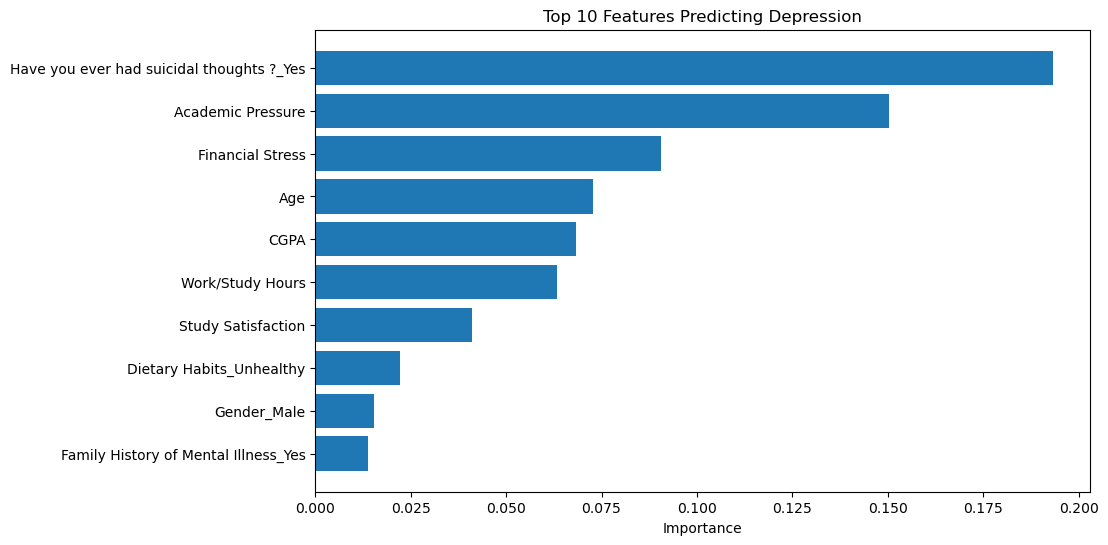

In [76]:
top_features = feature_importance.head(10)

plt.figure(figsize=(10,6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Importance")
plt.title("Top 10 Features Predicting Depression")
plt.gca().invert_yaxis()
plt.show()

And as we can see from the random forest methods we can see that the features that have the most effect on predicting depression are Having thoughts of suicide to be true as well as the academic pressure being the two top qualifiers of importance.

## The box plot relating academic pressure and depression

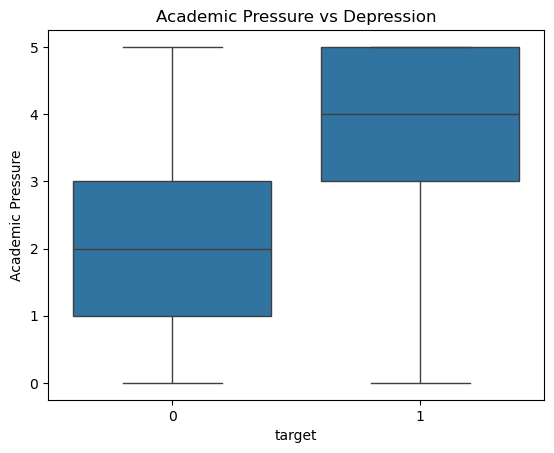

In [83]:
import seaborn as sns

sns.boxplot(x="target", y="Academic Pressure", data=df)

plt.title("Academic Pressure vs Depression")
plt.show()

As we can also see from this box plot here that students who do experience depression(represented by the 1) have a higher median for academic pressure and the middle 50% of students experience higher academic pressure on average when it comes to depression. Whereas on the left, that the people who do not have depression(shown by the 0) have a lower median academuc pressure and a lower middle 50% that experience academic pressure. 

## CONCLUSION

By usage of the machine learning models of Logistic Regression, Decision Trees and random forest trees, we can use them to predict the probability that a student would have depression given the criteria of the student. From the logistic regression and random forest models we can see that the largest factor that helps us predict what affects the students the most, which happens to be having suicidal thoughts. The same correlations can help us see what is less likely to impact the rates of depression in a studeny, such as their profession or the family history of mental illness. By testing through cross validation and consulting some confusion matricies I have learned that overall my Machine Learning models have an accuracy rate of just around the low to middle 80s, which is not that bad, I think there are measures to improve it further, but at my current level I do not know what those steps would be. It would most likely, though, involve moving around and adding in hyperparameters to make the model fit a tiny bit better. So I think I can solidly conclude that if a student has suicidal thoughts and a large amount of academic pressure, they are more likely to have depression. The regular decision tree has less accuracy ioverall than the other two methods I user, with an accuracy of 82 ish, but that is only 3% lower than the Logistic regression that I preformed, so I think the error there is just due to the variance of a regular decision tree. 